# Confident errors seen by four judges: Jev, Llama 3.3 70B, Gemma 4 31B and the generator itself

**Study:** the AAAI workshop paper (`specs/Protocol_for_AAAI_workshop.md`, Experiment 7), extending notebook 03, sections 9 and 10.
**Runs analysed:** `python -m fqsel judges-cbi` for Llama 3.3 70B, Gemma 4 31B and Qwen3-235B-A22B-Instruct-2507 (all Parasail, fp8), October 2026, next to Jev's scores from notebook 03.

Notebook 03 asked one judge, Jev, two questions about the strong model's **confident errors** (CBI: Qwen3-235B gives the same wrong answer in all five samples):

- **§9, judging the gold:** inside the unanimous stratum, where any agreement-based signal is blind, does the judge's support for the *gold* answer (R) separate reliable answers from CBI? Jev: AUROC 0.75.
- **§10, judging the model's answer:** does the judge's support for *Qwen's own answer* separate them? Jev: only 0.62, and in 90 of 281 CBI items Jev rejects the gold and supports Qwen.

This notebook repeats both analyses with three open-weight judges on exactly the same 1,730 unanimous items, and compares the four judges. Two are of other families (Llama 3.3 70B, Gemma 4 31B). The third is **the generator itself**: Qwen3-235B-A22B-Instruct-2507, the same weights that produced the five samples, now asked the judge's yes/no questions (a self-judging control). It asks whether the asymmetry (judging the gold works, judging the model's answer does not) and the generator–judge convergence (judges siding with Qwen against the verified gold) are properties of Jev or of LLM judges in general, and whether the generator endorses its own confident errors more than other judges do.

**Purely descriptive.** It reads only frozen snapshots, each verified against its `SHA256SUMS`:

- `code/runs/self_consistency_2026-10-25/` (Qwen's five samples per item);
- `code/runs/jev_on_qwen_2026-10-25/` (Jev's judgment of Qwen's modal answer);
- `code/runs/full_v2_2026-10-25/` (the pool and Jev under battery v2) and `code/runs/full_v0_2026-10-24/` (Jev under v0);
- `code/runs/judges_cbi_2026-10-30/` (Llama 3.3 70B and Gemma 4 31B, both arms);
- `code/runs/judges_cbi_qwen_2026-10-30/` (Qwen3-235B as judge, both arms).

It imports nothing from the pipeline (the CBI definitions are re-implemented here exactly as in notebook 03, and checked against its counts), calls no API, and changes no code, configuration or output. Its only outputs are this notebook and `notebooks/figures/cbi_judges_*.pdf`.

## 0. Design, and what differs from notebook 03

| | Jev (notebook 03) | Llama 3.3 70B, Gemma 4 31B, Qwen3-235B (these runs) |
| --- | --- | --- |
| Items | 1,730 unanimous (281 CBI); §10 also all 2,996 items | the same 1,730 unanimous items only (minimal scope) |
| Judging the gold | Q1, Q1′, Q2 v2, Q3 (and v0's Q2) from the full-pool runs | Q1, Q2 v2, Q3 |
| Judging Qwen's answer | Q1, Q1′, a separate run a day later | Q1, **in the same run and on the same endpoint** as the gold arm |
| Scoring | API probabilities (rounded to 0.01) | first-token log-probabilities, yes/no renormalised |
| Served by | TypeSafe (`jev-1.14.0`) | Parasail via OpenRouter, fp8 |

**Not reproduced for the new judges** (outside the minimal scope): the paraphrased support question (R′, Q1′), battery v0's I, the analyses over all items rather than the unanimous ones, and §9's selection comparison over the full subsample.

**The Qwen judge.** The planned same-family control, Qwen3-30B-A3B, could not be run: its only provider with log-probabilities (DekaLLM) rate-limited every request on two days. It was replaced (owner decision 2026-10-30) by the generator's own weights, Qwen3-235B-A22B-Instruct-2507. The generator's samples came from DeepInfra (fp8), which returns no log-probabilities; the judge ran on Parasail (fp8), so it is the same model on a different deployment, asked a different prompt (the judge's yes/no question, not the answering prompt) at temperature 0.

When Qwen's modal answer is the gold answer character for character (569 reliable items), the two Q1 prompts of a judge are identical and were sent once, so R_gold = R_model there by construction. This only concerns reliable items, never CBI.

**Status:** exploratory, pre-specified in the implementation plan (2026-10-30 02:42 UTC) before any score existed; not one of Protocol v1's pre-registered hypotheses.

## 1. Setup and integrity

In [1]:
import hashlib
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

CODE = Path.cwd().parent / "code"
SC_DIR = CODE / "runs" / "self_consistency_2026-10-25"
JQ_DIR = CODE / "runs" / "jev_on_qwen_2026-10-25"
V2_DIR = CODE / "runs" / "full_v2_2026-10-25"
V0_DIR = CODE / "runs" / "full_v0_2026-10-24"
JC_DIR = CODE / "runs" / "judges_cbi_2026-10-30"
QC_DIR = CODE / "runs" / "judges_cbi_qwen_2026-10-30"
FIG_DIR = Path.cwd() / "figures"
FIG_DIR.mkdir(exist_ok=True)
N_BOOT = 1000            # as notebook 03's §9-10 intervals
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

JUDGES = ["jev", "llama33_70b", "gemma4_31b", "qwen3_235b"]
OTHERS = JUDGES[:3]      # the judges of other families than the generator
LABEL = {"jev": "Jev", "llama33_70b": "Llama 3.3 70B", "gemma4_31b": "Gemma 4 31B", "qwen3_235b": "Qwen3-235B (generator)"}
SNAP_DIR = {"llama33_70b": JC_DIR, "gemma4_31b": JC_DIR, "qwen3_235b": QC_DIR}


def verify(folder):
    for line in (folder / "SHA256SUMS").read_text().splitlines():
        digest, rel = line.split(maxsplit=1)
        if hashlib.sha256((folder / rel).read_bytes()).hexdigest() != digest:
            return False
    return True

for d in (SC_DIR, JQ_DIR, V2_DIR, V0_DIR, JC_DIR, QC_DIR):
    print(f"{d.name:32s} checksums verified: {verify(d)}")

self_consistency_2026-10-25      checksums verified: True
jev_on_qwen_2026-10-25           checksums verified: True
full_v2_2026-10-25               checksums verified: True
full_v0_2026-10-24               checksums verified: True
judges_cbi_2026-10-30            checksums verified: True
judges_cbi_qwen_2026-10-30       checksums verified: True


**Rebuilding the unanimous stratum and the CBI labels exactly as notebook 03 does** (§6 and §9): an item is *unanimous* when 1 − H/log n over its five normalised answers is at least 0.8 (unparsed answers never agree), and *wrong* when fewer than 3 of its 5 samples match the gold. Three scorings, as in notebook 03: exact match (the pipeline's), exact match plus numeric equivalence (the suggested primary), and additionally token-F1 ≥ 0.8. Only items Jev also judged with Qwen's answer are kept, as in §10.

In [2]:
SCALE = {"thousand": 1e3, "million": 1e6, "billion": 1e9}


def toks(s):
    return re.findall(r"[a-z0-9]+(?:\.[0-9]+)?", (s or "").lower())


def token_f1(p, g):
    p, g = toks(p), toks(g)
    if not p or not g:
        return 0.0
    common = sum((Counter(p) & Counter(g)).values())
    if common == 0:
        return 0.0
    pr, rc = common / len(p), common / len(g)
    return 2 * pr * rc / (pr + rc)


def numbers(s):
    out = []
    for m in re.finditer(r"-?\d[\d,]*\.?\d*", s or ""):
        try:
            v = float(m.group().replace(",", "").rstrip("."))
        except ValueError:
            continue
        tail = (s[m.end():m.end() + 12] or "").strip().lower()
        mult = next((k for k in SCALE if tail.startswith(k)), None)
        out.append(v * (SCALE[mult] if mult else 1))
    return out


def numeric_equivalent(p, g, scale):
    gn, pn = numbers(g), numbers(p)
    if not gn or not pn or len(pn) < len(gn):
        return False
    targets = set(gn) | ({v * SCALE[scale] for v in gn} if scale in SCALE else set())
    return all(any(abs(v - w) <= 1e-6 * max(1.0, abs(w)) for w in targets) for v in pn)


def norm_ans(a):
    return re.sub(r"\s+", " ", a.strip().lower())


def entropy_consistency(answers):
    labels = [norm_ans(a) if a is not None else f"__unparsed_{i}" for i, a in enumerate(answers)]
    p = np.array(list(Counter(labels).values()), float) / len(labels)
    return float(1 - (-(p * np.log(p)).sum()) / np.log(len(labels)))


pool = pd.read_parquet(V2_DIR / "data" / "pool.parquet").set_index("item_id")
smp = pd.read_parquet(SC_DIR / "scores" / "sc_samples.parquet").join(pool[["gold_answer", "scale"]], on="item_id")
smp["f1"] = [1.0 if c else token_f1(a, g) for a, g, c in zip(smp["answer"], smp["gold_answer"], smp["correct"])]
smp["c_num"] = [bool(c) or (a is not None and numeric_equivalent(a, g, s or ""))
                for a, g, s, c in zip(smp["answer"], smp["gold_answer"], smp["scale"], smp["correct"])]
smp["c_f1"] = smp["c_num"] | (smp["f1"] >= 0.8)
g = smp.sort_values(["item_id", "k"]).groupby("item_id")
sc = pd.read_parquet(SC_DIR / "scores" / "self_consistency.parquet").set_index("item_id")
t = pd.DataFrame({"consistency": g["answer"].apply(lambda a: entropy_consistency(list(a))),
                  "acc_num": g["c_num"].mean(), "acc_f1": g["c_f1"].mean()}).join(sc[["modal_correct", "modal_answer"]])
jq = pd.read_parquet(JQ_DIR / "jev_on_qwen.parquet").set_index("item_id")
t = t.join(jq[["p_q1", "stated_answer"]], how="inner")
t = t[t["p_q1"].notna()]
una = t[t["consistency"] >= 0.8].join(pool[["dataset", "answer_type", "question", "gold_answer", "qa_tokens"]])
una["wrong_em"] = ~una["modal_correct"]
una["wrong_num"] = una["acc_num"] < 0.6          # the primary scoring: CBI
una["wrong_f1"] = una["acc_f1"] < 0.6
una["cbi"] = una["wrong_num"]
print(f"unanimous items: {len(una):,} (notebook 03: 1,730); CBI under the primary scoring: {int(una['cbi'].sum())} (notebook 03: 281)")
assert len(una) == 1730 and int(una["cbi"].sum()) == 281
assert (una["modal_answer"] == una["stated_answer"]).all()

unanimous items: 1,730 (notebook 03: 1,730); CBI under the primary scoring: 281 (notebook 03: 281)


**Scores per judge, aligned on the same items.** For every judge: `R_gold` (Q1 with the gold answer), `Q2_v2` (determinacy, no stated answer), `Q3` (consequence of the gold answer), `I_v2` = mean(Q2\_v2, Q3), and `R_model` (Q1 with Qwen's modal answer). Jev's come from its full-pool v2 run (gold) and its separate run on Qwen's answers (model); the open-weight judges' from one run each.

In [3]:
def jev_scores():
    lg = pd.read_parquet(V2_DIR / "scores" / "jev_scores_long.parquet")
    q = lg[lg["battery"] == "orig"].pivot(index="item_id", columns="question", values="p_yes")
    i = pd.read_parquet(V2_DIR / "scores" / "jev_scores.parquet").set_index("item_id")["I"]
    return pd.DataFrame({"R_gold": q["q1"], "Q2_v2": q["q2"], "Q3": q["q3"], "I_v2": i, "R_model": jq["p_q1"]})

S = {"jev": jev_scores().loc[una.index]}
manifest, long = {}, {}
for j in JUDGES[1:]:
    S[j] = pd.read_parquet(SNAP_DIR[j] / j / f"{j}.parquet").set_index("item_id").loc[una.index]
    long[j] = pd.read_parquet(SNAP_DIR[j] / j / f"{j}_long.parquet")
    manifest[j] = json.loads((SNAP_DIR[j] / j / f"{j}_manifest.json").read_text())
    assert (S[j]["cbi"] == una["cbi"]).all(), "the run's CBI labels must match this notebook's"
for j in JUDGES:
    assert S[j][["R_gold", "R_model", "Q2_v2", "Q3"]].notna().all().all(), j
print({LABEL[j]: len(S[j]) for j in JUDGES})

{'Jev': 1730, 'Llama 3.3 70B': 1730, 'Gemma 4 31B': 1730, 'Qwen3-235B (generator)': 1730}


## 2. Measurement quality of the three runs

In [4]:
rows = []
for j in JUDGES[1:]:
    m, lg = manifest[j], long[j]
    first = lg["top_token"].str.strip().str.lower()
    rows.append({"judge": LABEL[j], "endpoint": m["model_version"].split("@")[1], "served model": ", ".join(m["served_models"]),
                 "items": m["n_items"], "CBI": m["n_cbi"], "requests": m["n_distinct_requests"],
                 "P(yes) missing %": 100 * m["share_p_yes_null"], "yes/no mass, min": lg["mass"].min(),
                 "first token not yes/no %": 100 * (~first.isin(["yes", "no"])).mean(),
                 "repeat |ΔP|, gold arm": m["determinism"]["mean_abs_diff_by_arm"]["gold"],
                 "repeat |ΔP|, model arm": m["determinism"]["mean_abs_diff_by_arm"]["model"],
                 "input tokens (M)": m["input_tokens"] / 1e6, "cost $": m["cost_usd"]})
display(pd.DataFrame(rows).set_index("judge"))
same = {LABEL[j]: int((long[j].query("question == 'q1'").groupby("item_id")["request_id"].nunique() == 1).sum()) for j in JUDGES[1:]}
print("items whose gold and model Q1 shared one request (modal answer = gold string):", same)

,endpoint,served model,items,CBI,requests,P(yes) missing %,"yes/no mass, min",first token not yes/no %,"repeat |ΔP|, gold arm","repeat |ΔP|, model arm",input tokens (M),cost $
judge,,,,,,,,,,,,
Llama 3.3 70B,parasail/fp8,meta-llama/llama-3.3-70b-instruct,1730,281,6351,0.0,0.025,0.101,0.005,0.006,4.848,0.747
Gemma 4 31B,parasail/fp8,google/gemma-4-31b-it,1730,281,6351,0.0,1.000,0.000,0.010,0.004,5.379,0.607
Qwen3-235B (generator),parasail/fp8,qwen/qwen3-235b-a22b-2507,1730,281,6351,0.0,0.947,0.000,0.009,0.006,5.215,0.566


items whose gold and model Q1 shared one request (modal answer = gold string): {'Llama 3.3 70B': 569, 'Gemma 4 31B': 569, 'Qwen3-235B (generator)': 569}


## 3. §9 for four judges: judging the gold inside the blind spot

Within the 1,730 unanimous items, every item is maximally consistent, so any agreement-based signal has AUROC 0.5. The question is whether a judge's scores **of the gold answer** still separate reliable items (Q1 quadrant, label 1) from CBI (label 0). Bootstrap intervals over items (1,000 resamples), as in notebook 03.

In [5]:
rng = np.random.default_rng(20261030)
BOOT = [rng.integers(0, len(una), len(una)) for _ in range(N_BOOT)]   # shared resamples: paired differences
Y = (~una["cbi"]).to_numpy().astype(int)


def auc_boot(score, mask=None):
    s = np.asarray(score, float)
    idx_all = np.arange(len(s)) if mask is None else np.flatnonzero(mask)
    point = roc_auc_score(Y[idx_all], s[idx_all])
    if mask is None:
        reps = np.array([roc_auc_score(Y[b], s[b]) for b in BOOT])
    else:
        r2 = np.random.default_rng(1)
        reps = np.array([roc_auc_score(Y[b], s[b]) for b in (r2.choice(idx_all, len(idx_all)) for _ in range(N_BOOT))])
    return point, reps


def ci(point, reps):
    lo, hi = np.percentile(reps, [2.5, 97.5])
    return f"{point:.3f} [{lo:.3f}, {hi:.3f}]"

SUBSETS = {"all": None, "FinQA": (una["dataset"] == "finqa").to_numpy(), "TAT-QA": (una["dataset"] == "tatqa").to_numpy(),
           "arith": (una["answer_type"] == "arith").to_numpy(), "lookup": (una["answer_type"] == "lookup").to_numpy()}
AUC = {(j, c, sub): auc_boot(S[j][c].to_numpy(), m) for j in JUDGES for c in ("R_gold", "Q2_v2", "Q3", "I_v2", "R_model")
       for sub, m in SUBSETS.items()}
gold = pd.DataFrame({(LABEL[j], c): {f"{sub} (n={len(una) if m is None else int(m.sum())}, CBI {int(una['cbi'].sum()) if m is None else int(una['cbi'].to_numpy()[m].sum())})": ci(*AUC[(j, c, sub)])
                                      for sub, m in SUBSETS.items()} for j in JUDGES for c in ("R_gold", "Q2_v2", "Q3", "I_v2")}).T
with pd.option_context("display.max_colwidth", None):
    display(gold)
med = pd.DataFrame({LABEL[j]: {"median R_gold, reliable": S[j].loc[~una["cbi"], "R_gold"].median(),
                               "median R_gold, CBI": S[j].loc[una["cbi"], "R_gold"].median()} for j in JUDGES}).T
display(med)

all (n=1730, CBI 281) FinQA (n=844, CBI 156)  \
Jev                    R_gold  0.749 [0.711, 0.785]   0.858 [0.820, 0.892]   
                       Q2_v2   0.632 [0.595, 0.667]   0.599 [0.552, 0.649]   
                       Q3      0.641 [0.609, 0.674]   0.643 [0.602, 0.688]   
                       I_v2    0.656 [0.622, 0.690]   0.620 [0.574, 0.667]   
Llama 3.3 70B          R_gold  0.643 [0.597, 0.685]   0.802 [0.760, 0.842]   
                       Q2_v2   0.579 [0.540, 0.615]   0.521 [0.470, 0.573]   
                       Q3      0.628 [0.590, 0.664]   0.708 [0.665, 0.751]   
                       I_v2    0.627 [0.591, 0.663]   0.597 [0.546, 0.649]   
Gemma 4 31B            R_gold  0.729 [0.689, 0.761]   0.854 [0.817, 0.887]   
                       Q2_v2   0.599 [0.561, 0.635]   0.572 [0.521, 0.623]   
                       Q3      0.605 [0.574, 0.640]   0.580 [0.540, 0.620]   
                       I_v2    0.659 [0.625, 0.694]   0.607 [0.559, 0.656]   
Qwen3-235B (generator) R_gold  0.658 [0.616, 0.697]   0.820 [0.784, 0.853]   
                       Q2_v2   0.583 [0.546, 0.620]   0.571 [0.516, 0.623]   
                       Q3      0.591 [0.554, 0.629]   0.611 [0.566, 0.659]   
                       I_v2    0.607 [0.571, 0.642]   0.593 [0.541, 0.644]   

                              TAT-QA (n=886, CBI 125) arith (n=1191, CBI 188)  \
Jev                    R_gold    0.629 [0.571, 0.690]    0.864 [0.831, 0.895]   
                       Q2_v2     0.651 [0.601, 0.700]    0.621 [0.576, 0.666]   
                       Q3        0.647 [0.597, 0.698]    0.627 [0.586, 0.667]   
                       I_v2      0.676 [0.623, 0.724]    0.636 [0.597, 0.678]   
Llama 3.3 70B          R_gold    0.457 [0.395, 0.530]    0.811 [0.777, 0.845]   
                       Q2_v2     0.619 [0.568, 0.668]    0.555 [0.512, 0.598]   
                       Q3        0.542 [0.487, 0.598]    0.701 [0.664, 0.740]   
                       I_v2      0.646 [0.598, 0.691]    0.631 [0.590, 0.672]   
Gemma 4 31B            R_gold    0.587 [0.535, 0.644]    0.863 [0.831, 0.891]   
                       Q2_v2     0.606 [0.553, 0.659]    0.602 [0.557, 0.651]   
                       Q3        0.656 [0.606, 0.704]    0.585 [0.544, 0.625]   
                       I_v2      0.695 [0.644, 0.742]    0.637 [0.594, 0.683]   
Qwen3-235B (generator) R_gold    0.482 [0.424, 0.547]    0.809 [0.776, 0.841]   
                       Q2_v2     0.587 [0.535, 0.638]    0.594 [0.548, 0.637]   
                       Q3        0.560 [0.507, 0.616]    0.612 [0.570, 0.655]   
                       I_v2      0.602 [0.549, 0.656]    0.612 [0.571, 0.654]   

                              lookup (n=539, CBI 93)  
Jev                    R_gold   0.550 [0.478, 0.620]  
                       Q2_v2    0.735 [0.685, 0.782]  
                       Q3       0.671 [0.608, 0.732]  
                       I_v2     0.744 [0.687, 0.793]  
Llama 3.3 70B          R_gold   0.428 [0.359, 0.499]  
                       Q2_v2    0.656 [0.596, 0.711]  
                       Q3       0.529 [0.462, 0.595]  
                       I_v2     0.652 [0.587, 0.708]  
Gemma 4 31B            R_gold   0.535 [0.485, 0.587]  
                       Q2_v2    0.628 [0.572, 0.683]  
                       Q3       0.647 [0.588, 0.704]  
                       I_v2     0.705 [0.638, 0.764]  
Qwen3-235B (generator) R_gold   0.484 [0.416, 0.554]  
                       Q2_v2    0.634 [0.576, 0.690]  
                       Q3       0.551 [0.487, 0.621]  
                       I_v2     0.629 [0.568, 0.687]

,"median R_gold, reliable","median R_gold, CBI"
Jev,0.98,0.800
Llama 3.3 70B,1.00,0.987
Gemma 4 31B,1.00,0.999
Qwen3-235B (generator),1.00,0.994


In [6]:
coef = {}
for j in JUDGES:
    d = una[["dataset", "answer_type", "qa_tokens", "cbi"]].join(S[j][["R_gold", "Q2_v2", "Q3"]])
    d["cbi_i"] = d["cbi"].astype(int)
    d["finqa"] = (d["dataset"] == "finqa").astype(int)
    d["lookup"] = (d["answer_type"] == "lookup").astype(int)
    d["log_tokens"] = np.log(d["qa_tokens"])
    for c in ("R_gold", "Q2_v2", "Q3", "log_tokens"):
        d[f"z_{c}"] = (d[c] - d[c].mean()) / d[c].std()
    fit = smf.logit("cbi_i ~ z_R_gold + z_Q2_v2 + z_Q3 + z_log_tokens + finqa + lookup", data=d).fit(disp=False)
    coef[LABEL[j]] = pd.Series({k: f"{np.exp(v):.2f} [{np.exp(lo):.2f}, {np.exp(hi):.2f}]" for k, v, lo, hi in
                                zip(fit.params.index, fit.params, fit.conf_int()[0], fit.conf_int()[1]) if k != "Intercept"})
    coef[LABEL[j]]["pseudo-R²"] = f"{fit.prsquared:.3f}"
print("Logit of CBI (vs reliable) among unanimous items; odds ratios per SD (standardised predictors), 95% CI:")
display(pd.DataFrame(coef))

Logit of CBI (vs reliable) among unanimous items; odds ratios per SD (standardised predictors), 95% CI:


,Jev,Llama 3.3 70B,Gemma 4 31B,Qwen3-235B (generator)
z_R_gold,"0.33 [0.28, 0.38]","0.48 [0.42, 0.55]","0.39 [0.35, 0.45]","0.51 [0.46, 0.58]"
z_Q2_v2,"0.87 [0.75, 1.01]","1.09 [0.95, 1.25]","1.08 [0.95, 1.23]","0.97 [0.86, 1.09]"
z_Q3,"0.95 [0.81, 1.11]","0.80 [0.71, 0.90]","0.73 [0.65, 0.82]","0.86 [0.76, 0.97]"
z_log_tokens,"0.94 [0.78, 1.14]","0.94 [0.79, 1.13]","0.92 [0.77, 1.10]","0.97 [0.81, 1.16]"
finqa,"1.34 [0.84, 2.16]","1.81 [1.18, 2.76]","1.69 [1.07, 2.66]","1.85 [1.21, 2.83]"
lookup,"3.69 [2.40, 5.69]","2.86 [1.92, 4.26]","2.96 [1.95, 4.51]","2.68 [1.80, 3.98]"
pseudo-R²,0.242,0.120,0.191,0.111


**Findings (§9 for four judges): judging the gold works for every judge.**
- **R separates reliable unanimous answers from confident errors for all four judges:** AUROC 0.75 (Jev), 0.73 (Gemma 4 31B), 0.66 (Qwen3-235B, the generator) and 0.64 (Llama 3.3 70B), where any agreement-based signal is at 0.5.
- **The strength sits in FinQA and arithmetic, as for Jev.** On FinQA all four reach 0.80–0.86, and on arithmetic items 0.81–0.86. On TAT-QA and on lookup items R barely separates for any judge (0.43–0.63); Llama's and Qwen's TAT-QA values (0.46, 0.48) are at chance. This is consistent with notebook 03's explanation for Jev (span answers, R compressed near 1).
- **The open-weight judges compress R even more than Jev.** Their median R on CBI items is 0.99–1.00, against Jev's 0.80; their separation comes from the minority of items they doubt.
- **Determinacy and consequence add little** (Q2 v2: 0.58–0.63; Q3: 0.59–0.64; I v2: 0.60–0.66). In the joint logit R dominates for every judge (odds ratio per SD 0.33–0.51); Q3 adds something for the open-weight judges (0.73–0.86), determinacy for none, and lookup items are about three times as likely to be CBI under every judge.

## 4. §10 for four judges: judging Qwen's own answer

The label-free deployment question: shown only the model's answer, can a judge tell the reliable unanimous answers from the confident errors? Primary metric (as pre-specified for Jev in notebook 03 and for the new judges in the plan): within the unanimous items, the AUROC of the judge's P(yes | Q1) **on Qwen's answer** for reliable vs CBI, under the primary scoring. Next to it, the same judge's AUROC on the gold, and the **paired difference** (gold − model) over the same bootstrap resamples.

In [7]:
rows = {}
for j in JUDGES:
    rows[LABEL[j]] = {f"{sub}: judging Qwen's answer": ci(*AUC[(j, "R_model", sub)]) for sub in SUBSETS}
    g0, m0 = AUC[(j, "R_gold", "all")], AUC[(j, "R_model", "all")]
    rows[LABEL[j]]["all: judging the gold"] = ci(*g0)
    rows[LABEL[j]]["all: gold − model (paired)"] = ci(g0[0] - m0[0], g0[1] - m0[1])
prim = pd.DataFrame(rows).T
with pd.option_context("display.max_colwidth", None):
    display(prim[["all: judging Qwen's answer", "all: judging the gold", "all: gold − model (paired)",
                  "FinQA: judging Qwen's answer", "TAT-QA: judging Qwen's answer", "arith: judging Qwen's answer", "lookup: judging Qwen's answer"]])

sens = {}
for j in JUDGES:
    sens[LABEL[j]] = {name: f"{roc_auc_score((~una[col]).astype(int), S[j]['R_model']):.3f}"
                      for name, col in (("exact match", "wrong_em"), ("exact + numeric (primary)", "wrong_num"), ("token-F1 ≥ 0.8", "wrong_f1"))}
print("AUROC of judging Qwen's answer under the three scorings (point estimates):")
display(pd.DataFrame(sens).T)

,all: judging Qwen's answer,all: judging the gold,all: gold − model (paired),FinQA: judging Qwen's answer,TAT-QA: judging Qwen's answer,arith: judging Qwen's answer,lookup: judging Qwen's answer
Jev,"0.621 [0.586, 0.658]","0.749 [0.711, 0.785]","0.129 [0.086, 0.170]","0.586 [0.534, 0.638]","0.647 [0.595, 0.699]","0.616 [0.571, 0.661]","0.649 [0.584, 0.713]"
Llama 3.3 70B,"0.493 [0.451, 0.534]","0.643 [0.597, 0.685]","0.150 [0.110, 0.190]","0.494 [0.436, 0.554]","0.436 [0.376, 0.495]","0.519 [0.464, 0.572]","0.461 [0.384, 0.536]"
Gemma 4 31B,"0.560 [0.523, 0.595]","0.729 [0.689, 0.761]","0.168 [0.129, 0.207]","0.544 [0.492, 0.594]","0.556 [0.504, 0.609]","0.565 [0.518, 0.610]","0.569 [0.515, 0.618]"
Qwen3-235B (generator),"0.497 [0.455, 0.539]","0.658 [0.616, 0.697]","0.160 [0.122, 0.200]","0.483 [0.425, 0.538]","0.480 [0.424, 0.534]","0.487 [0.438, 0.540]","0.567 [0.500, 0.631]"


AUROC of judging Qwen's answer under the three scorings (point estimates):


,exact match,exact + numeric (primary),token-F1 ≥ 0.8
Jev,0.602,0.621,0.640
Llama 3.3 70B,0.470,0.493,0.508
Gemma 4 31B,0.540,0.560,0.567
Qwen3-235B (generator),0.470,0.497,0.502


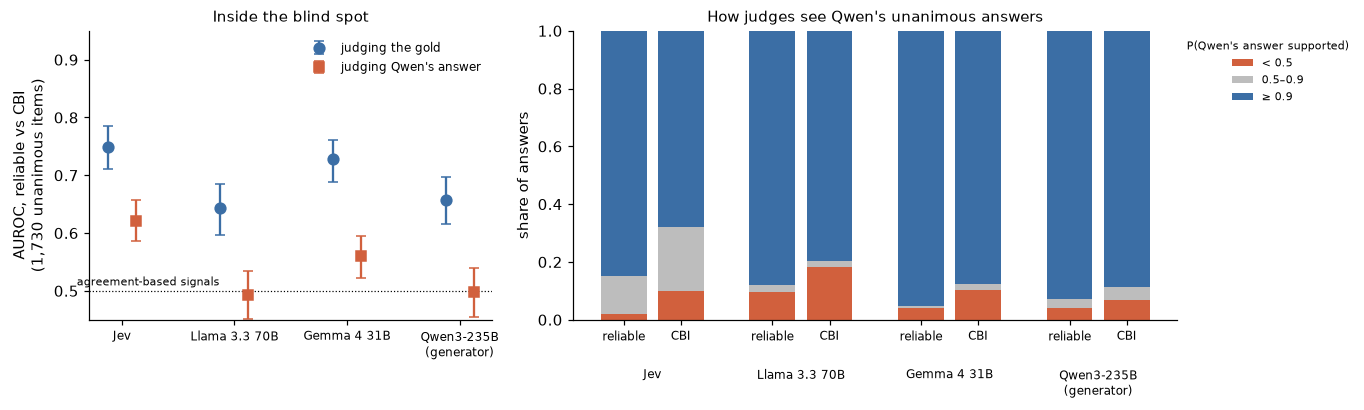

n  median P(supported)  share ≥ 0.9  \
Jev                    reliable  1449.0                 0.98        0.849   
                       CBI        281.0                 0.96        0.680   
Llama 3.3 70B          reliable  1449.0                 1.00        0.881   
                       CBI        281.0                 1.00        0.797   
Gemma 4 31B            reliable  1449.0                 1.00        0.952   
                       CBI        281.0                 1.00        0.875   
Qwen3-235B (generator) reliable  1449.0                 1.00        0.928   
                       CBI        281.0                 1.00        0.886   

                                 share < 0.5  
Jev                    reliable        0.019  
                       CBI             0.100  
Llama 3.3 70B          reliable        0.097  
                       CBI             0.181  
Gemma 4 31B            reliable        0.041  
                       CBI             0.103  
Qwen3-235B (generator) reliable        0.042  
                       CBI             0.068

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
x = np.arange(len(JUDGES))
for k, (col, lab, mk) in enumerate([("R_gold", "judging the gold", "o"), ("R_model", "judging Qwen's answer", "s")]):
    pts = [AUC[(j, col, "all")] for j in JUDGES]
    y = np.array([p[0] for p in pts])
    err = np.array([[p[0] - np.percentile(p[1], 2.5), np.percentile(p[1], 97.5) - p[0]] for p in pts]).T
    ax.errorbar(x + (k - 0.5) * 0.25, y, yerr=err, fmt=mk, ms=7, capsize=3, color=["#3b6ea5", "#d1603d"][k], label=lab)
ax.axhline(0.5, ls=":", color="black", lw=0.8)
ax.text(-0.4, 0.505, "agreement-based signals", fontsize=7, ha="left", va="bottom")
ax.set_xticks(x, [LABEL[j].replace(" (", "\n(") for j in JUDGES], fontsize=8)
ax.set_ylabel("AUROC, reliable vs CBI\n(1,730 unanimous items)")
ax.set_ylim(0.45, 0.95)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.set_title("Inside the blind spot", fontsize=10)

ax = axes[1]
bands = [("< 0.5", lambda r: r < 0.5, "#d1603d"), ("0.5–0.9", lambda r: (r >= 0.5) & (r < 0.9), "#bdbdbd"),
         ("≥ 0.9", lambda r: r >= 0.9, "#3b6ea5")]
pos, labels = [], []
for k, j in enumerate(JUDGES):
    for m, (lab, mask) in enumerate((("reliable", ~una["cbi"]), ("CBI", una["cbi"]))):
        x0 = k * 2.6 + m
        r = S[j].loc[mask, "R_model"]
        bottom = 0.0
        for name, f, col in bands:
            h = float(f(r).mean())
            ax.bar(x0, h, 0.8, bottom=bottom, color=col, label=name if (k, m) == (0, 0) else None)
            bottom += h
        pos.append(x0)
        labels.append(f"{lab}\n({LABEL[j]})" if m == 0 else lab)
ax.set_xticks(pos, [f"{'reliable' if i % 2 == 0 else 'CBI'}" for i in range(len(pos))], fontsize=8)
for k, j in enumerate(JUDGES):
    ax.text(k * 2.6 + 0.5, -0.17, LABEL[j].replace(" (", "\n("), ha="center", va="top", fontsize=8, transform=ax.get_xaxis_transform())
ax.set_ylabel("share of answers")
ax.set_ylim(0, 1)
ax.legend(title="P(Qwen's answer supported)", frameon=False, fontsize=7, title_fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("How judges see Qwen's unanimous answers", fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "cbi_judges_auroc.pdf", bbox_inches="tight")
plt.show()

dist = pd.DataFrame({(LABEL[j], lab): {"n": int(mask.sum()), "median P(supported)": S[j].loc[mask, "R_model"].median(),
                                       "share ≥ 0.9": (S[j].loc[mask, "R_model"] >= 0.9).mean(),
                                       "share < 0.5": (S[j].loc[mask, "R_model"] < 0.5).mean()}
                     for j in JUDGES for lab, mask in (("reliable", ~una["cbi"]), ("CBI", una["cbi"]))}).T
display(dist)

**Findings (§10 for four judges): judging the model's answer does not, and the asymmetry is general.**
- **Judging Qwen's own answer separates reliable answers from confident errors far less well for every judge:** AUROC 0.62 (Jev), 0.56 (Gemma), 0.50 (Qwen judging itself, at chance) and 0.49 (Llama, at chance).
- **The gap between judging the gold and judging the model's answer is the same for all four judges** and clearly above zero: +0.13 [0.09, 0.17] for Jev, +0.15 [0.11, 0.19] for Llama, +0.16 [0.12, 0.20] for Qwen, +0.17 [0.13, 0.21] for Gemma, paired over the same items. Notebook 03's central result is not a property of Jev, and it holds when the judge is the generator itself.
- **The open-weight judges endorse confident errors even more readily than Jev:** 80% (Llama), 88% (Gemma) and 89% (Qwen) of CBI answers get P(supported) ≥ 0.9, against Jev's 68%; for every judge the median on CBI is the same as on reliable answers (0.96–1.00).
- **Robust to the scoring:** under exact match, the primary scoring and token-F1, the ordering and the near-chance level stay the same for every judge (Llama 0.47–0.51, Qwen 0.47–0.50, Gemma 0.54–0.57, Jev 0.60–0.64).

## 5. Joint verdicts within the confident errors, and convergence across judges

Within the 281 CBI items, each judge's verdicts on the gold and on Qwen's answer at P(yes) ≥ 0.5, as in notebook 03's table (Jev: 163 both supported, 90 only Qwen's, 14 only the gold, 14 neither). Then: **do the judges side with Qwen on the same items?**

In [9]:
cbi_ids = una.index[una["cbi"]]
CELL = {(False, True): "only Qwen's answer supported", (True, True): "both supported",
        (True, False): "only the gold supported", (False, False): "neither supported"}
verdict = {j: pd.Series([CELL[(g >= 0.5, m >= 0.5)] for g, m in zip(S[j].loc[cbi_ids, "R_gold"], S[j].loc[cbi_ids, "R_model"])],
                        index=cbi_ids) for j in JUDGES}
order = list(CELL.values())
table = pd.DataFrame({LABEL[j]: verdict[j].value_counts().reindex(order, fill_value=0) for j in JUDGES})
table.loc["total"] = table.sum()
display(table)
by_ds = pd.DataFrame({LABEL[j]: verdict[j].eq("only Qwen's answer supported").groupby(una.loc[cbi_ids, "dataset"]).sum() for j in JUDGES})
print("'only Qwen's answer supported' by dataset:")
display(by_ds)

side = {j: set(verdict[j].index[verdict[j] == "only Qwen's answer supported"]) for j in JUDGES}
rows = {}
for a in JUDGES:
    rows[LABEL[a]] = {LABEL[b]: (f"{len(side[a] & side[b])}" + ("" if a == b else f" (Jaccard {len(side[a] & side[b]) / max(len(side[a] | side[b]), 1):.2f})"))
                      for b in JUDGES}
print("CBI items on which a judge sides with Qwen against the gold, and their overlap between judges:")
display(pd.DataFrame(rows))
all3 = set.intersection(*(side[j] for j in OTHERS))                  # the three judges of other families
all4 = all3 & side["qwen3_235b"]
n_any = len(set.union(*(side[j] for j in JUDGES)))
print(f"all three other-family judges side with Qwen: {len(all3)} items; all four judges: {len(all4)}; "
      f"at least one judge: {n_any} of {len(cbi_ids)} CBI items")
print(f"of the {len(all3)} items all three other-family judges share, the generator itself sides with its answer on "
      f"{len(all3 & side['qwen3_235b'])}")
# expected overlap of the open-weight judges with Jev if they chose independently, for reference
for j in JUDGES[1:]:
    exp = len(side["jev"]) * len(side[j]) / len(cbi_ids)
    print(f"{LABEL[j]}: overlap with Jev {len(side['jev'] & side[j])}, expected under independence {exp:.1f} "
          f"({len(side['jev'] & side[j]) / exp:.1f}x)" if exp else "")

,Jev,Llama 3.3 70B,Gemma 4 31B,Qwen3-235B (generator)
only Qwen's answer supported,90,89,101,77
both supported,163,141,151,185
only the gold supported,14,18,14,6
neither supported,14,33,15,13
total,281,281,281,281


'only Qwen's answer supported' by dataset:


,Jev,Llama 3.3 70B,Gemma 4 31B,Qwen3-235B (generator)
dataset,,,,
finqa,72,71,80,62
tatqa,18,18,21,15


CBI items on which a judge sides with Qwen against the gold, and their overlap between judges:


,Jev,Llama 3.3 70B,Gemma 4 31B,Qwen3-235B (generator)
Jev,90,55 (Jaccard 0.44),71 (Jaccard 0.59),51 (Jaccard 0.44)
Llama 3.3 70B,55 (Jaccard 0.44),89,63 (Jaccard 0.50),55 (Jaccard 0.50)
Gemma 4 31B,71 (Jaccard 0.59),63 (Jaccard 0.50),101,60 (Jaccard 0.51)
Qwen3-235B (generator),51 (Jaccard 0.44),55 (Jaccard 0.50),60 (Jaccard 0.51),77


all three other-family judges side with Qwen: 50 items; all four judges: 41; at least one judge: 151 of 281 CBI items
of the 50 items all three other-family judges share, the generator itself sides with its answer on 41
Llama 3.3 70B: overlap with Jev 55, expected under independence 28.5 (1.9x)
Gemma 4 31B: overlap with Jev 71, expected under independence 32.3 (2.2x)
Qwen3-235B (generator): overlap with Jev 51, expected under independence 24.7 (2.1x)


In [10]:
ex = una.loc[sorted(all3)][["dataset", "answer_type", "question", "gold_answer", "modal_answer"]].copy()
for j in JUDGES:
    ex[f"{LABEL[j]}: gold"] = S[j].loc[ex.index, "R_gold"].round(2)
    ex[f"{LABEL[j]}: Qwen"] = S[j].loc[ex.index, "R_model"].round(2)
with pd.option_context("display.max_colwidth", 70):
    display(ex.rename(columns={"modal_answer": "Qwen's answer"}).head(10))
print(f"{len(ex)} items where all three other-family judges reject the gold and support Qwen's answer (first 10 shown).")

,dataset,answer_type,question,gold_answer,Qwen's answer,Jev: gold,Jev: Qwen,Llama 3.3 70B: gold,Llama 3.3 70B: Qwen,Gemma 4 31B: gold,Gemma 4 31B: Qwen,Qwen3-235B (generator): gold,Qwen3-235B (generator): Qwen
item_id,,,,,,,,,,,,,
finqa:AAPL/2010/page_42.pdf-2,finqa,arith,by how much did total other income and expense decrease from 2008 ...,47.4%,$294 million,0.24,1.00,0.00,0.85,0.46,1.0,0.96,1.0
finqa:AAPL/2012/page_24.pdf-2,finqa,arith,what was the cumulative total return on the s&p 500 between septem...,5,$105,0.24,0.96,0.00,1.00,0.00,1.0,1.00,1.0
finqa:AMAT/2016/page_32.pdf-2,finqa,arith,what is the total return if 1000000 is invested in s&p500 in 2011 ...,152100,1152100,0.44,0.95,0.00,1.00,0.00,1.0,0.90,1.0
finqa:AMT/2005/page_32.pdf-1,finqa,arith,based on the information what was the number of stock warrants iss...,0.06,1.0 million,0.04,0.92,0.00,1.00,0.00,1.0,0.00,1.0
finqa:AON/2007/page_184.pdf-2,finqa,arith,what is the rent expense reported in the financial statement of 2007?,408,$368 million,0.06,0.98,0.00,1.00,0.00,1.0,0.11,1.0
finqa:AON/2007/page_185.pdf-4,finqa,arith,what is the percentual decrease observed in the future minimum ren...,-0.13%,13.25%,0.14,0.98,0.00,1.00,0.00,1.0,0.00,1.0
finqa:AOS/2016/page_19.pdf-2,finqa,arith,what was the difference in total return for the five year period e...,98%,303.0,0.04,1.00,0.05,0.62,0.00,1.0,0.98,1.0
finqa:AWK/2017/page_136.pdf-4,finqa,arith,in 2017 what was the ratio of the removal costs to the total regul...,5.3,0.1893,0.08,0.79,0.00,1.00,0.00,1.0,0.95,1.0
finqa:AWK/2018/page_172.pdf-4,finqa,arith,what percentage of future annual commitments related to minimum qu...,957%,66.98,0.04,0.86,0.00,1.00,0.00,1.0,0.00,1.0


50 items where all three other-family judges reject the gold and support Qwen's answer (first 10 shown).


**Findings: judges side with Qwen against the gold, and largely on the same items.**
- **All four judges have the same verdict profile within the 281 CBI items:** "only Qwen's answer supported" 90 (Jev), 89 (Llama), 101 (Gemma), 77 (Qwen); "both supported" 141–185; a clean catch of Qwen's error ("only the gold supported") just 6–18. No judge catches more than about 6% of the confident errors outright; the generator catches 6 (2%).
- **The items where judges side with Qwen overlap far beyond chance:** with Jev's 90, Llama shares 55 (1.9× the overlap expected if they chose independently), Gemma 71 (2.2×) and Qwen 51 (2.1×). **50 items are shared by the three judges of other families** (40 FinQA arithmetic, 5 TAT-QA arithmetic, 5 TAT-QA lookup), and the generator sides with its own answer on 41 of them.
- **The shared items look like item problems rather than model errors.** The first ones are the examples notebook 03 already flagged: a gold percentage against Qwen's dollar amount for "by how much did … decrease", the gain against the final value for "total return if 1,000,000 is invested", and gold values off in scale or definition.
- **For the paper:** four judges, three families plus the generator itself, converge with the generator against the execution-verified gold on the same items. That makes "two models share an arithmetic slip" a much weaker explanation and "the item, not the model, is the problem" a stronger one. The hand audit's stratum A (sampled from Jev's 90) covers this set; the 50 items shared by the three other-family judges (41 with the generator too) are the natural core of that check.

## 5b. Does the generator endorse its own confident errors more?

The self-judging control. Within the 281 CBI items, for each judge: how often it gives Qwen's wrong answer P(supported) ≥ 0.9, how often it rejects the verified gold (P < 0.5), and how often it prefers Qwen's answer to the gold (P on Qwen's answer strictly above P on the gold; ties count as no preference). Each is compared with the generator's own rate over the same items, with a paired bootstrap over CBI items (1,000 resamples). The reliable unanimous items are shown as the reference: a judge that endorses everything shows high rates there too.

In [11]:
cbi_mask = una["cbi"].to_numpy()
rng_s = np.random.default_rng(20261031)
BOOT_CBI = [rng_s.integers(0, int(cbi_mask.sum()), int(cbi_mask.sum())) for _ in range(N_BOOT)]
RATES = {"Qwen's answer ≥ 0.9": lambda d: d["R_model"] >= 0.9,
         "gold < 0.5": lambda d: d["R_gold"] < 0.5,
         "prefers Qwen's answer": lambda d: d["R_model"] > d["R_gold"]}
rows, diff = {}, {}
for j in JUDGES:
    d_cbi, d_rel = S[j][cbi_mask], S[j][~cbi_mask]
    rows[LABEL[j]] = {**{f"CBI: {k}": f(d_cbi).mean() for k, f in RATES.items()},
                      **{f"reliable: {k}": f(d_rel).mean() for k, f in RATES.items()}}
q = S["qwen3_235b"][cbi_mask]
for j in OTHERS:
    o = S[j][cbi_mask]
    diff[f"Qwen − {LABEL[j]}"] = {}
    for k, f in RATES.items():
        qa, oa = f(q).to_numpy().astype(float), f(o).to_numpy().astype(float)
        reps = np.array([qa[b].mean() - oa[b].mean() for b in BOOT_CBI])
        diff[f"Qwen − {LABEL[j]}"][f"CBI: {k}"] = ci(qa.mean() - oa.mean(), reps)
display(pd.DataFrame(rows).T)
print("Generator minus other judge, on the same 281 CBI items (paired bootstrap 95% CI):")
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(diff).T)

,CBI: Qwen's answer ≥ 0.9,CBI: gold < 0.5,CBI: prefers Qwen's answer,reliable: Qwen's answer ≥ 0.9,reliable: gold < 0.5,reliable: prefers Qwen's answer
Jev,0.680,0.370,0.605,0.849,0.028,0.275
Llama 3.3 70B,0.797,0.434,0.683,0.881,0.117,0.361
Gemma 4 31B,0.875,0.413,0.609,0.952,0.055,0.212
Qwen3-235B (generator),0.886,0.320,0.680,0.928,0.063,0.355


Generator minus other judge, on the same 281 CBI items (paired bootstrap 95% CI):


,CBI: Qwen's answer ≥ 0.9,CBI: gold < 0.5,CBI: prefers Qwen's answer
Qwen − Jev,"0.206 [0.149, 0.267]","-0.050 [-0.103, 0.007]","0.075 [0.018, 0.128]"
Qwen − Llama 3.3 70B,"0.089 [0.046, 0.135]","-0.114 [-0.164, -0.060]","-0.004 [-0.057, 0.050]"
Qwen − Gemma 4 31B,"0.011 [-0.032, 0.053]","-0.093 [-0.146, -0.043]","0.071 [0.018, 0.125]"


**Findings: the generator as judge is lenient, not distinctively self-favouring.**
- **It endorses its own confident errors the most:** 89% get P(supported) ≥ 0.9, 21 points more than Jev [15, 27] and 9 more than Llama [5, 14], but no more than Gemma (+1 [−3, +5]).
- **But it rejects the verified gold the least:** P(gold) < 0.5 on 32% of CBI items, 9–11 points below Gemma and Llama. So it most often supports *both* answers (185 of 281) and sides with itself against the gold on the fewest items (77, against 89–101).
- **Its preference for its own answer over the gold is not specific to itself:** it scores Qwen's answer above the gold on 68% of CBI items, the same as Llama (68%) and 7 points above Jev and Gemma; Llama and Qwen show the same tendency on reliable items too (36% each).
- **Its judgments track Llama's most closely** (Spearman 0.80 judging the gold, 0.77 judging Qwen's answer), more than any other pair.
- **For the paper:** a self-judge cannot tell its confident errors from its reliable answers (AUROC 0.50), yet judging the gold still works for it (0.66). The failure of output verification is general to LLM judges, not a self-preference artefact; and the generator does not "defend" its errors against the gold more than other judges do.

## 6. Likely scoring artefacts, and agreement between judges

In [12]:
ok = ~una["wrong_em"]
art = una["wrong_em"] & ~una["wrong_f1"]          # wrong by exact match only
clear = una["wrong_f1"]                           # wrong under every scoring
rows = {}
for j in JUDGES:
    r = S[j]["R_model"]
    rows[LABEL[j]] = {"correct: median": r[ok].median(), "likely artefact: median": r[art].median(),
                      "clear error: median": r[clear].median(),
                      "likely artefact: share ≥ 0.9": (r[art] >= 0.9).mean(), "clear error: share ≥ 0.9": (r[clear] >= 0.9).mean()}
print(f"unanimous items: correct {int(ok.sum())}, likely scoring artefacts {int(art.sum())}, clear errors {int(clear.sum())}")
display(pd.DataFrame(rows).T)

agree = {}
for col, name in (("R_gold", "judging the gold"), ("R_model", "judging Qwen's answer")):
    m = pd.DataFrame({LABEL[j]: S[j][col] for j in JUDGES}).corr(method="spearman")
    agree[name] = {f"{LABEL[a]} – {LABEL[b]}": m.loc[LABEL[a], LABEL[b]] for i, a in enumerate(JUDGES) for b in JUDGES[i + 1:]}
print("Spearman correlation between judges on the 1,730 unanimous items:")
display(pd.DataFrame(agree).round(3))

unanimous items: correct 1422, likely scoring artefacts 63, clear errors 245


,correct: median,likely artefact: median,clear error: median,likely artefact: share ≥ 0.9,clear error: share ≥ 0.9
Jev,0.98,0.98,0.95,0.889,0.653
Llama 3.3 70B,1.00,1.00,1.00,0.889,0.792
Gemma 4 31B,1.00,1.00,1.00,0.952,0.865
Qwen3-235B (generator),1.00,1.00,1.00,0.873,0.894


Spearman correlation between judges on the 1,730 unanimous items:


,judging the gold,judging Qwen's answer
Jev – Llama 3.3 70B,0.472,0.392
Jev – Gemma 4 31B,0.494,0.377
Jev – Qwen3-235B (generator),0.447,0.378
Llama 3.3 70B – Gemma 4 31B,0.693,0.597
Llama 3.3 70B – Qwen3-235B (generator),0.803,0.774
Gemma 4 31B – Qwen3-235B (generator),0.670,0.574


**Findings: scoring artefacts and agreement.**
- **All four judges treat likely scoring artefacts as correct** (median P(supported) 0.98–1.00, 87–95% at ≥ 0.9), confirming notebook 03's evidence for counting numerically equivalent spans as correct.
- **But they also endorse clear errors** (65–89% at ≥ 0.9), so support separates artefacts from genuine errors only partly, and not at all for the generator. The gap is largest for Jev (89% vs 65% at ≥ 0.9), smaller for Llama (89% vs 79%) and Gemma (95% vs 87%), and absent for Qwen (87% vs 89%).
- **The open-weight judges agree with each other more than with Jev** (ρ 0.67–0.80 judging the gold, 0.57–0.77 judging Qwen's answer, against 0.45–0.49 and 0.38–0.39 with Jev), consistent with their shared scoring mechanism and serving.

## 7. Summary for the paper

In [13]:
summ = pd.DataFrame({LABEL[j]: {
    "AUROC judging the gold (R)": f"{AUC[(j, 'R_gold', 'all')][0]:.2f}",
    "AUROC judging Qwen's answer": f"{AUC[(j, 'R_model', 'all')][0]:.2f}",
    "gold − model": f"{AUC[(j, 'R_gold', 'all')][0] - AUC[(j, 'R_model', 'all')][0]:+.2f}",
    "FinQA: gold / model": f"{AUC[(j, 'R_gold', 'FinQA')][0]:.2f} / {AUC[(j, 'R_model', 'FinQA')][0]:.2f}",
    "CBI with Qwen's answer ≥ 0.9": f"{(S[j].loc[una['cbi'], 'R_model'] >= 0.9).mean():.0%}",
    "sides with Qwen (of 281)": len(side[j]),
} for j in JUDGES}).T
display(summ)

def a(j, c, sub="all"):
    return AUC[(j, c, sub)][0]

print(f"""
METHODS — CBI with several judges. On the {len(una):,} items Qwen3-235B answered unanimously ({int(una['cbi'].sum())} of them
confident errors), three open-weight judges, Llama 3.3 70B, Gemma 4 31B and the generator itself (Qwen3-235B;
fp8, one provider, first-token log-probabilities), scored the support question twice in the same run: with the
verified gold answer and with Qwen's modal answer. Jev's scores come from notebook 03.

RESULTS — Judging the gold separates reliable unanimous answers from confident errors for every judge
(AUROC: Jev {a('jev','R_gold'):.2f}, Llama {a('llama33_70b','R_gold'):.2f}, Gemma {a('gemma4_31b','R_gold'):.2f}, Qwen {a('qwen3_235b','R_gold'):.2f}),
while judging Qwen's own answer does so far less (Jev {a('jev','R_model'):.2f}, Llama {a('llama33_70b','R_model'):.2f},
Gemma {a('gemma4_31b','R_model'):.2f}, Qwen {a('qwen3_235b','R_model'):.2f}). Within the confident errors, the judges reject the gold
and support Qwen's answer on {len(side['jev'])}, {len(side['llama33_70b'])}, {len(side['gemma4_31b'])} and {len(side['qwen3_235b'])} items
respectively; {len(all3)} items are shared by the three other-family judges, {len(all4)} of them also by the generator.
""")

,AUROC judging the gold (R),AUROC judging Qwen's answer,gold − model,FinQA: gold / model,CBI with Qwen's answer ≥ 0.9,sides with Qwen (of 281)
Jev,0.75,0.62,+0.13,0.86 / 0.59,68%,90
Llama 3.3 70B,0.64,0.49,+0.15,0.80 / 0.49,80%,89
Gemma 4 31B,0.73,0.56,+0.17,0.85 / 0.54,88%,101
Qwen3-235B (generator),0.66,0.50,+0.16,0.82 / 0.48,89%,77



METHODS — CBI with several judges. On the 1,730 items Qwen3-235B answered unanimously (281 of them
confident errors), three open-weight judges, Llama 3.3 70B, Gemma 4 31B and the generator itself (Qwen3-235B;
fp8, one provider, first-token log-probabilities), scored the support question twice in the same run: with the
verified gold answer and with Qwen's modal answer. Jev's scores come from notebook 03.

RESULTS — Judging the gold separates reliable unanimous answers from confident errors for every judge
(AUROC: Jev 0.75, Llama 0.64, Gemma 0.73, Qwen 0.66),
while judging Qwen's own answer does so far less (Jev 0.62, Llama 0.49,
Gemma 0.56, Qwen 0.50). Within the confident errors, the judges reject the gold
and support Qwen's answer on 90, 89, 101 and 77 items
respectively; 50 items are shared by the three other-family judges, 41 of them also by the generator.



**Summary.**
1. **Judging the gold works, judging the model's answer does not, for all four judges, including the generator judging itself.** The paired gap is +0.13 to +0.17 AUROC for Jev, Llama, Qwen and Gemma alike; the open-weight judges are at or near chance when judging Qwen's answer (0.49–0.56), and the generator exactly at chance (0.50).
2. **Confident errors look correct to every judge**: 68–89% of them get P(supported) ≥ 0.9, the most for the generator itself.
3. **Judges converge with the generator against the verified gold on the same items**: about a third of CBI items per judge, overlapping about twice as often as chance; 50 items are shared by the three other-family judges, 40 of them FinQA arithmetic, and the generator agrees with them on 41.
4. **No distinct self-preference:** the generator is the most lenient judge but rejects the gold least, and prefers its own answer no more than Llama does.
5. **Practical conclusion, now across three judge families and a self-judge:** an LLM judge is useful for auditing labelled data (judging the gold), not for certifying a model's unlabelled outputs.

**Open:** whether the 50 shared items are model errors or item problems is for the hand audit.

## 8. Limitations

1. **The self-judging control is the same weights, not the same deployment or prompt.** Qwen3-235B judged on Parasail (fp8); its samples came from DeepInfra (fp8), which returns no log-probabilities. The planned smaller same-family judge (Qwen3-30B) could not be run.
2. **Minimal scope.** No paraphrased support question, no v0 battery and no all-items analysis for the new judges; Jev's rows include them in notebook 03.
3. **Different scoring mechanisms.** Jev returns API probabilities rounded to 0.01; the open-weight judges' come from first-token log-probabilities. Only rank-based measures (AUROC, Spearman) are compared.
4. **fp8 serving, one provider.** All three open-weight judges were served by Parasail in fp8.
5. **Jev's two arms come from different runs a day apart;** each open-weight judge's arms come from one run on one endpoint.
6. **Identical prompts on 569 reliable items** (modal answer = gold string) make R_gold = R_model there by construction for the open-weight judges, which sent that request once; Jev was asked the same question in its two runs, so its two values there differ only by call-to-call noise. This does not touch CBI items.
7. **"CBI" depends on the gold.** Judges siding with Qwen may be catching questionable gold labels rather than missing model errors; the hand audit decides.
8. **Exploratory**, pre-specified before any score, not among Protocol v1's pre-registered hypotheses.